# Semantic Target-Head Retraining — Workstream 40.4 / 40.5

**Model-preparation repository · 2026-11-20**

This notebook presents the target-head retraining work requested for Workstream 40:

1. the **92-trace participant export** from Supabase, its audited provenance retrofit and the
   framework verifier gate;
2. **dataset `v2.2.0-participant`** (14 approved target IDs, session-bounded splits,
   training-only class weights);
3. the **40.3 window/horizon re-confirmation** on the enlarged participant set;
4. the **14-class semantic target head** and the freeze / partial / full ablation;
5. held-out evaluation with per-class, macro, majority, task-level, lead-time and calibration
   metrics;
6. **ONNX + INT8 export**, bundle v2 and the framework handoff.

> **Evidence boundary.** These are participant-declared traces used as participant-derived
> *engineering* evidence. No participant identifier is approved (ADR-023), the split unit is the
> session (ADR-031), the sample is small and the label distribution is extremely imbalanced.
> No participant-held-out generalisation is claimed, and model accuracy is **not** evidence of
> usability, task performance or intervention benefit.

In [1]:
from pathlib import Path
import json
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

# Keep plotting and font caches inside the workspace; the home cache is read-only here.
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".metrics" / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(ROOT / ".cache"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 80)

DATASET_VERSION = "v2.2.0-participant"
DATASET_DIR = ROOT / ".data" / "processed" / DATASET_VERSION
EXPORT_DIR = ROOT / ".data" / "raw" / "collected-2026-11-20"
RETROFIT_DIR = ROOT / ".data" / "raw" / "participant-2026-11-20"
VERIFIED_DIR = ROOT / ".data" / "raw" / "participant-verified-2026-11-20"
WH_REPORT = ROOT / "docs" / "experiments" / "window-horizon-participant-r2"
HEAD_REPORT = ROOT / "docs" / "experiments" / "semantic-head" / "semantic-head-evaluation.json"
BUNDLE = ROOT / "models" / "bundles" / "v2.0.0" / "bundle.json"
FRAMEWORK = ROOT.parent / "edge-aui-framework"

import torch
print("project root :", ROOT)
print("python       :", sys.version.split()[0])
print("torch        :", torch.__version__, "| device available:",
      "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))

project root : /Users/user/Workspace/MivaCS/FYP/model-preparation
python       : 3.13.12
torch        : 2.15.0 | device available: mps


## 1. Collection and provenance gate

The Supabase project `bfntyqahujplvcowjdmh` (`edge-aui`) holds **92 sessions**, all trace schema
**1.4.0**, exported read-only with `edge-aui-framework/scripts/export-traces.mjs`.

The database rows and the trace bodies disagree about provenance for part of the set: the
deployment's collection-mode correction landed after some captures, so 44 traces declare
`scripted` in the body and 5 session rows declare `participant` while the body still says
`scripted`. Under the researcher instruction recorded for this run, **the whole export is a
participant capture set**; the scripted declarations are treated as upload-mode oversights. A
local, audited retrofit rewrote only `session.provenance` and `metadata.provenance` on the
exported copy. The database was not modified; `participantId` stays null.

The framework verifier then decided which traces are analysis input. A failed trace remains a
record but is not evidence.

In [2]:
export_manifest = json.loads((EXPORT_DIR / "export-manifest.json").read_text())
retrofit_manifest = json.loads((RETROFIT_DIR / "retrofit-manifest.json").read_text())
verification = json.loads((VERIFIED_DIR / "verification-manifest.json").read_text())

sessions = export_manifest["sessions"]
exported = len(sessions)
body_provenance = {}
for entry in sessions:
    path = EXPORT_DIR / f"experiment-trace-{entry['sessionId']}.json"
    trace = json.loads(path.read_text())
    body_provenance[entry["sessionId"]] = (
        trace["session"].get("provenance"),
        trace["metadata"].get("provenance"),
    )

summary = pd.DataFrame([
    ["Exported sessions", exported, "trace schema 1.4.0, no truncation"],
    ["Body provenance = scripted", sum(1 for p in body_provenance.values() if p[0] == "scripted"),
     "treated as upload-mode oversight under the recorded authority"],
    ["Body provenance = participant", sum(1 for p in body_provenance.values() if p[0] == "participant"),
     "declared participant at capture"],
    ["Retrofit corrected", retrofit_manifest["counts"]["corrected"],
     "session/metadata provenance rewritten on the local copy"],
    ["Verifier passed", verification["counts"]["verified"], "analysis input"],
    ["Verifier excluded", verification["counts"]["excluded"], "capture defects, not renamed as evidence"],
], columns=["Stage", "Count", "Note"])
display(summary)

excluded = [s for s in verification["sessions"] if s.get("status") != "verified"]
exclusion_rows = []
for entry in excluded:
    detail = (entry.get("detail") or "").split("—")[0].strip()
    exclusion_rows.append({
        "session": entry["session_id"][:12] + "…",
        "reason": detail.replace("[✗ FAIL]", "").strip(),
    })
display(pd.DataFrame(exclusion_rows).value_counts("reason").rename("sessions").to_frame())
display(Markdown(
    f"**Analysis input: {verification['counts']['verified']} of {exported} sessions.** "
    "The 15 exclusions are capture defects (window attribution, structural validity, task "
    "lifecycle), not provenance relabelling."
))

,Stage,Count,Note
0,Exported sessions,92,"trace schema 1.4.0, no truncation"
1,Body provenance = scripted,44,treated as upload-mode oversight under the recorded authority
2,Body provenance = participant,48,declared participant at capture
3,Retrofit corrected,44,session/metadata provenance rewritten on the local copy
4,Verifier passed,77,analysis input
5,Verifier excluded,15,"capture defects, not renamed as evidence"


,sessions
reason,
prediction_window_attribution,11
structural_validity,3
task_lifecycle_consistency,1


**Analysis input: 77 of 92 sessions.** The 15 exclusions are capture defects (window attribution, structural validity, task lifecycle), not provenance relabelling.

## 2. Dataset `v2.2.0-participant`

The dataset was rebuilt with the verified traces (session-bounded split before window
generation, seed 42). Labels are the approved **14 target IDs** (ADR-030). The runtime's 15th ID
`inspect_help` is recorded evidence and is **excluded**, not relabelled; its exclusion count is
reported. Class weights are resolved on the training partition only.

The manifest no longer claims `scripted_substitute_testbed`: its source type and claim boundary
are derived from the rows' declared provenance.

In [3]:
manifest = json.loads((DATASET_DIR / "manifest.json").read_text())
dataset = pd.read_parquet(DATASET_DIR / "target_semantic_dataset.parquet")

split = manifest["split_summary"]
semantics = manifest["target_semantics"]
vocabulary = semantics["target_vocabulary"]

overview = pd.DataFrame([
    ["Dataset version", manifest["dataset_version"]],
    ["Content hash", manifest["content_hash"]],
    ["Rows", f"{len(dataset):,}"],
    ["Sessions", f"{split['session_counts']['total']} "
                 f"(train {split['session_counts']['train']}, val {split['session_counts']['val']}, "
                 f"test {split['session_counts']['test']})"],
    ["Source data type", manifest["source_data_type"]],
    ["Split unit", split["split_unit"]],
    ["Label key", split["label_key"]],
    ["Target vocabulary", f"{len(vocabulary)} IDs · {semantics['target_vocabulary_version']}"],
    ["Recorded vocabulary", semantics["recorded_vocabulary_version"]],
    ["Excluded inspect_help windows", semantics["excluded_recorded_only"]],
    ["Excluded incomplete lookahead", semantics["excluded_incomplete_lookahead"]],
    ["Label sources", json.dumps(semantics["label_sources"])],
], columns=["Field", "Value"])
display(overview)

dist = split["class_distribution"]
class_table = pd.DataFrame([
    {
        "Outcome": name,
        "Train": dist["train"]["counts"][name],
        "Val": dist["val"]["counts"][name],
        "Test": dist["test"]["counts"][name],
        "Weight (train-only)": round(manifest["class_weights"]["weights"][name], 3),
    }
    for name in vocabulary
])
class_table["Total"] = class_table[["Train", "Val", "Test"]].sum(axis=1)
display(class_table)
display(Markdown(
    f"**`NO_OUTCOME` is {dist['train']['majority_percentage']:.1f}% of training rows**; "
    f"`{', '.join(name for name in vocabulary if dist['test']['counts'][name] == 0)}` have zero "
    "test support. Macro-F1 is therefore reported over supported classes, and absent classes "
    "are named rather than scored as zero F1."
))

,Field,Value
0,Dataset version,v2.2.0-participant
1,Content hash,7ebb11cac86d
2,Rows,"9,686"
3,Sessions,"77 (train 54, val 12, test 11)"
4,Source data type,participant_capture
5,Split unit,session
6,Label key,target_task_outcome
7,Target vocabulary,14 IDs · testbed-semantic-target/1.0.0
8,Recorded vocabulary,testbed-semantic/1.0.0
9,Excluded inspect_help windows,0


,Outcome,Train,Val,Test,Weight (train-only),Total
0,navigate_overview,4,0,0,34.194,4
1,navigate_analytics,55,14,7,7.365,76
2,navigate_reports,46,11,12,8.548,69
3,select_report,79,24,19,5.379,122
4,open_filter_section,305,63,60,1.520,428
5,close_filter_section,9,0,0,25.195,9
6,select_region,128,32,16,3.469,176
7,select_date_range,218,46,73,2.100,337
8,select_category,93,18,23,4.648,134
9,apply_filter,134,27,24,3.324,185


**`NO_OUTCOME` is 82.6% of training rows**; `navigate_overview, close_filter_section, backtrack` have zero test support. Macro-F1 is therefore reported over supported classes, and absent classes are named rather than scored as zero F1.

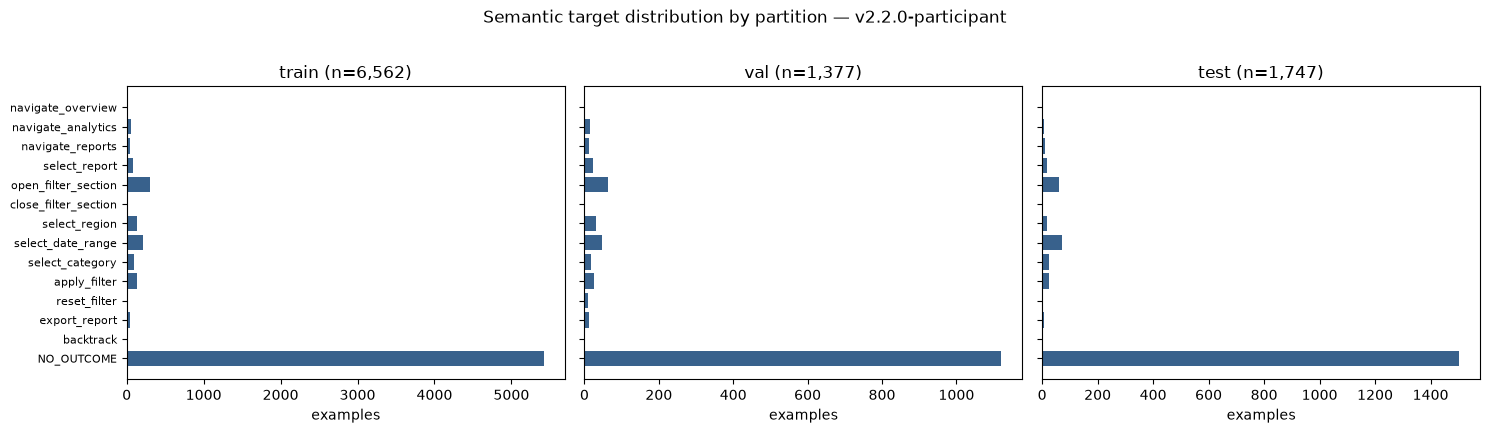

Partition,test,train,val
Task,,,
TD1,313,1459,465
TD2,804,1574,87
TD3,373,2364,638
TD4,257,1165,187


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, part in zip(axes, ("train", "val", "test")):
    counts = [dist[part]["counts"][name] for name in vocabulary]
    ax.barh(range(len(vocabulary)), counts, color="#38618c")
    ax.set_yticks(range(len(vocabulary)))
    ax.set_yticklabels(vocabulary, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f"{part} (n={dist[part]['total_examples']:,})")
    ax.set_xlabel("examples")
fig.suptitle("Semantic target distribution by partition — v2.2.0-participant", y=1.02)
plt.tight_layout()
plt.show()

task_rows = []
for part in ("train", "val", "test"):
    coverage = split.get("task_coverage", {}).get(part)
    if coverage:
        for task, count in coverage.items():
            task_rows.append({"Partition": part, "Task": task, "Examples": count})
if task_rows:
    display(pd.DataFrame(task_rows).pivot(index="Task", columns="Partition", values="Examples"))

## 3. Window/horizon re-confirmation (Task 40.3)

The four pre-declared configurations were re-run on the 77 verified sessions. Selection uses
only the pre-declared criteria (training coverage, largest-class share, median lead time, then
declared order). It does not use the validation or test partitions.

In [5]:
wh = json.loads((WH_REPORT / "window-horizon-results.json").read_text())
rows = []
for experiment in wh["experiments"]:
    config = experiment["config"]
    metrics = experiment["metrics"]
    rows.append({
        "ID": config["id"],
        "History": f"{config['history_windows']}x500 ms",
        "Lookahead (ms)": f"{config['lookahead_ms'][0]}–{config['lookahead_ms'][1]}",
        "Examples": metrics["total_examples"],
        "Train classes ≥5": metrics["train_classes_with_min_support"],
        "Largest train share": f"{metrics['train_max_class_share'] * 100:.1f}%",
        "Lead median (ms)": round(metrics["lead_time_median_ms"]),
        "Majority macro-F1": round(metrics["macro_f1"], 4),
    })
wh_table = pd.DataFrame(rows)
display(wh_table)
selected = wh["selection"]
display(Markdown(
    f"**Selected: {selected['config']['id']} ({selected['config']['label']}).** "
    f"`provisional={selected.get('provisional')}` — the same configuration wins again, but the "
    "margin between the top configurations remains inside sampling noise. The configuration is "
    "used for the retraining run and is not claimed to be final."
))

,ID,History,Lookahead (ms),Examples,Train classes ≥5,Largest train share,Lead median (ms),Majority macro-F1
0,A,8x500 ms,500–1500,9994,12,82.9%,1025,0.0842
1,B,8x500 ms,1000–2000,9845,12,82.7%,1517,0.0841
2,C,4x500 ms,500–1500,10302,12,83.3%,1025,0.0843
3,D,12x500 ms,500–1500,9686,12,82.6%,1023,0.0841


**Selected: D (12x500 ms, [500, 1500] ms).** `provisional=True` — the same configuration wins again, but the margin between the top configurations remains inside sampling noise. The configuration is used for the retraining run and is not claimed to be final.

## 4. Head architecture

`TargetSemanticHead` is the same context-conditioned MLP contract as the legacy intervention
head — `[h_T, C] -> logits` — with the output pinned to the **14 approved target IDs**
(ADR-030), not the 15-ID recorded vocabulary and not the 5 intervention classes. The GRU
backbone is unchanged; `models/foundational_gru.pth` is loaded, never overwritten.

In [6]:
from training import EdgeAUIGRU, TargetSemanticHead, SEMANTIC_NUM_CLASSES
from semantic_targets import TARGET_VOCABULARY, TARGET_VOCABULARY_VERSION

model = EdgeAUIGRU(
    input_dim=18, hidden_dim=64, num_layers=2,
    num_classes=SEMANTIC_NUM_CLASSES,
    head=TargetSemanticHead(hidden_dim=64),
)
with torch.no_grad():
    logits = model(torch.randn(2, 12, 18), context=torch.randn(2, 6))

parameter_counts = pd.DataFrame([
    ["GRU backbone", sum(p.numel() for p in model.gru.parameters())],
    ["Semantic head", sum(p.numel() for p in model.head.parameters())],
    ["Total", sum(p.numel() for p in model.parameters())],
], columns=["Component", "Parameters"])
display(parameter_counts)
display(Markdown(
    f"Head output classes: **{SEMANTIC_NUM_CLASSES}** · vocabulary version "
    f"`{TARGET_VOCABULARY_VERSION}` · forward output `{tuple(logits.shape)}`."
))

,Component,Parameters
0,GRU backbone,41088
1,Semantic head,5454
2,Total,46542


Head output classes: **14** · vocabulary version `testbed-semantic-target/1.0.0` · forward output `(2, 14)`.

## 5. Training protocol and ablation

E1/E2/E3 are the pre-declared freeze / partial / full arms. Each arm keeps the best epoch by
**validation** macro-F1 and evaluates the **test** partition once, after the checkpoint is
frozen. Seeds, epoch count, class weights, dataset hash, history and horizon are recorded next
to each checkpoint.

,Arm,Best epoch,Val macro-F1,Test accuracy,Test macro-F1,Test weighted-F1,Majority macro-F1,ECE
0,E1,22,0.1681,0.1053,0.1105,0.0802,0.0841,0.2796
1,E2,30,0.1836,0.1271,0.1297,0.1102,0.0841,0.2913
2,E3,10,0.1627,0.1093,0.0767,0.0987,0.0841,0.2603


**Selected arm: E2** (highest validation macro-F1, 0.1836). Test is reported below for this arm only.

,Training configuration,Value
0,Head class count,14
1,Dataset,v2.2.0-participant (7ebb11cac86d)
2,Split unit,session
3,History / horizon,"12 x 500 ms / [500.0, 1500.0] ms"
4,Seed / epochs,42 / 50
5,Learning-rate scheme,"{""scheme"": ""partial_finetuning"", ""backbone_terminal_layer"": ""_l1"", ""gru_lr"":..."
6,Class-weight source,train_partition_only
7,Best epoch (val),30


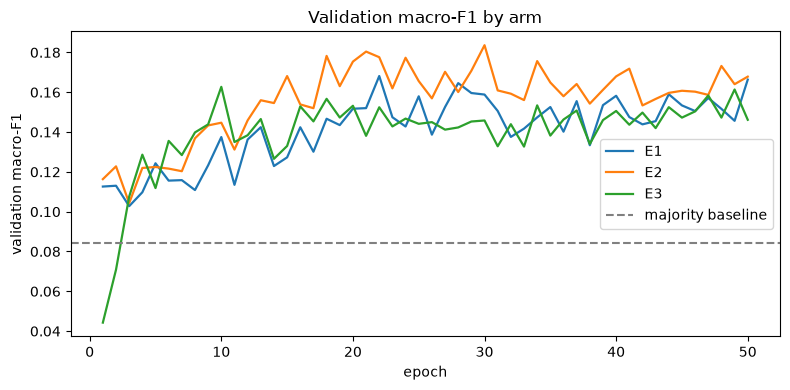

In [7]:
report = json.loads(HEAD_REPORT.read_text())
ablation = report["ablation"]

arm_rows = []
for arm in ablation:
    test = arm["test"]
    arm_rows.append({
        "Arm": arm["experiment"].upper(),
        "Best epoch": arm["best_epoch"],
        "Val macro-F1": round(arm["val"]["macro_f1"], 4),
        "Test accuracy": round(test["accuracy"], 4),
        "Test macro-F1": round(test["macro_f1"], 4),
        "Test weighted-F1": round(test["weighted_f1"], 4),
        "Majority macro-F1": round(test["majority_macro_f1"], 4),
        "ECE": round(test["ece"], 4),
    })
ablation_table = pd.DataFrame(arm_rows)
display(ablation_table)

# The export/held-out arm is selected on validation macro-F1 only.
best_arm = max(ablation, key=lambda arm: arm["val"]["macro_f1"])
best_test = best_arm["test"]
training = best_arm["training_config"]
display(Markdown(
    f"**Selected arm: {best_arm['experiment'].upper()}** (highest validation macro-F1, "
    f"{best_arm['val']['macro_f1']:.4f}). Test is reported below for this arm only."
))

config_table = pd.DataFrame([
    ["Head class count", training["head_class_count"]],
    ["Dataset", f"{training['dataset_version']} ({training['dataset_content_hash']})"],
    ["Split unit", training["split_unit"]],
    ["History / horizon", f"{training['history_windows']} x 500 ms / {training['lookahead_horizon_ms']} ms"],
    ["Seed / epochs", f"{training['seed']} / {training['epochs']}"],
    ["Learning-rate scheme", json.dumps(training["learning_rate_scheme"])],
    ["Class-weight source", training["class_weights_source"]],
    ["Best epoch (val)", training["best_epoch"]],
], columns=["Training configuration", "Value"])
display(config_table)

fig, ax = plt.subplots(figsize=(8, 4))
for experiment in ("e1", "e2", "e3"):
    path = ROOT / "models" / f"semantic_head_{experiment}_training.json"
    if path.is_file():
        history = json.loads(path.read_text())["history"]
        ax.plot(range(1, len(history["val_macro_f1"]) + 1), history["val_macro_f1"],
                label=experiment.upper(), linewidth=1.6)
ax.axhline(best_test["majority_macro_f1"], color="grey", linestyle="--",
           label="majority baseline")
ax.set_xlabel("epoch")
ax.set_ylabel("validation macro-F1")
ax.set_title("Validation macro-F1 by arm")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Held-out evaluation

Test metrics for the validation-selected arm. Sessions are the split unit; a session never
appears in two partitions. Absent classes are named, not scored. The majority baseline is
computed from the training partition's most frequent class and applied to the test partition.

In [8]:
per_class = best_test["per_class"]
prf = pd.DataFrame([
    {
        "Outcome": name,
        "Precision": round(values["precision"], 3),
        "Recall": round(values["recall"], 3),
        "F1": round(values["f1"], 3),
        "Support": values["support"],
        "Status": "absent" if values["support"] == 0 else "",
    }
    for name, values in per_class.items()
])
display(prf)

majority = best_test["majority_baseline"]
overall = pd.DataFrame([
    ["Test accuracy", round(best_test["accuracy"], 4)],
    ["Majority accuracy", round(majority["accuracy"], 4)],
    ["Macro-F1 (supported)", round(best_test["macro_f1"], 4)],
    ["Majority macro-F1", round(majority["macro_f1"], 4)],
    ["Macro-F1 (all 14)", round(best_test["macro_f1_all"], 4)],
    ["Weighted-F1", round(best_test["weighted_f1"], 4)],
    ["Top-3 accuracy", round(best_test["ranking"]["hr@3"], 4)],
    ["MRR", round(best_test["ranking"]["mrr"], 4)],
    ["Samples", str(best_test["n_samples"])],
], columns=["Metric", "Value"])
display(overall)
display(Markdown(
    f"Absent in test: `{', '.join(best_test['absent_classes'])}`. The model trades majority-class "
    "accuracy for rare-class recall: macro-F1 is above the majority baseline, accuracy is far "
    "below it. That trade-off is expected under the declared training-only class weights."
))

,Outcome,Precision,Recall,F1,Support,Status
0,navigate_overview,0.000,0.000,0.000,0,absent
1,navigate_analytics,0.072,1.000,0.135,7,
2,navigate_reports,0.094,0.417,0.154,12,
3,select_report,0.135,0.789,0.231,19,
4,open_filter_section,0.125,0.317,0.179,60,
5,close_filter_section,0.000,0.000,0.000,0,absent
6,select_region,0.035,0.625,0.067,16,
7,select_date_range,0.112,0.890,0.199,73,
8,select_category,0.133,0.652,0.221,23,
9,apply_filter,0.013,0.083,0.023,24,


,Metric,Value
0,Test accuracy,0.1271
1,Majority accuracy,0.8603
2,Macro-F1 (supported),0.1297
3,Majority macro-F1,0.0841
4,Macro-F1 (all 14),0.1019
5,Weighted-F1,0.1102
6,Top-3 accuracy,0.759
7,MRR,0.4724
8,Samples,1747


Absent in test: `navigate_overview, close_filter_section, backtrack`. The model trades majority-class accuracy for rare-class recall: macro-F1 is above the majority baseline, accuracy is far below it. That trade-off is expected under the declared training-only class weights.

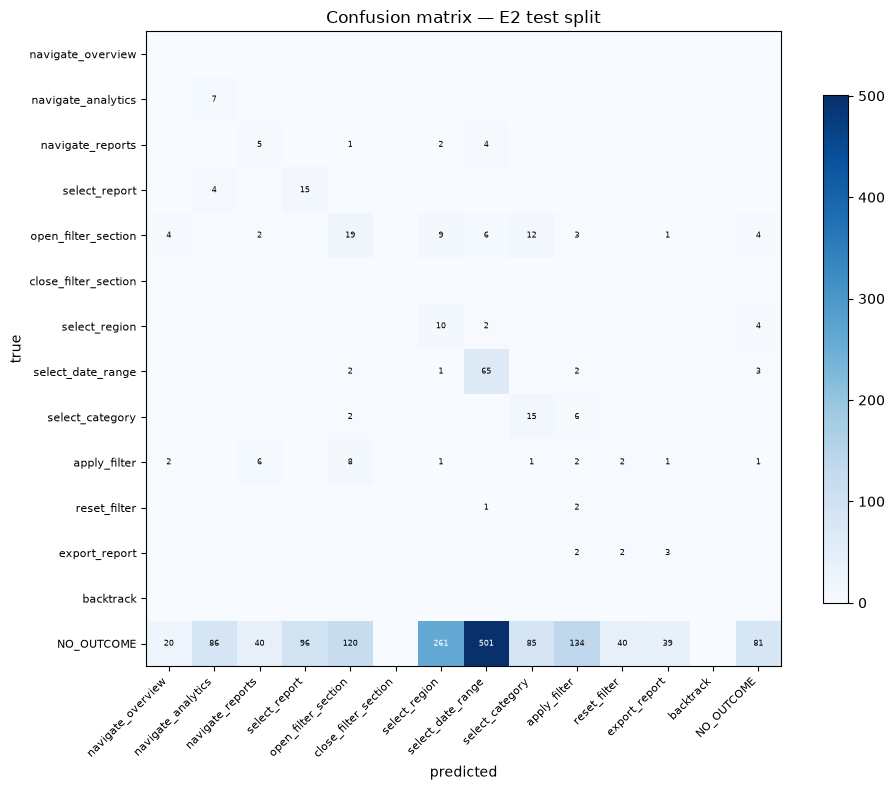

In [9]:
labels = list(per_class)
matrix = np.asarray(best_test["confusion_matrix"])
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(matrix, cmap="Blues")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Confusion matrix — {best_arm['experiment'].upper()} test split")
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        if matrix[row, column]:
            ax.text(column, row, int(matrix[row, column]), ha="center", va="center",
                    fontsize=6, color="white" if matrix[row, column] > matrix.max() / 2 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

In [10]:
task_table = pd.DataFrame([
    {
        "Task": task,
        "Examples": values["n_samples"],
        "Accuracy": round(values["accuracy"], 3),
        "Macro-F1": round(values["macro_f1"], 3),
        "Absent classes": len(values["absent_classes"]),
    }
    for task, values in sorted(best_test["task_level"].items())
])
display(task_table)

lead = best_test["lead_time"]["per_class"]
lead_table = pd.DataFrame([
    {
        "Outcome": name,
        "Labels with lead time": values["count"],
        "Median (ms)": None if values["median_ms"] is None else round(values["median_ms"]),
        "P25 (ms)": None if values["p25_ms"] is None else round(values["p25_ms"]),
        "P75 (ms)": None if values["p75_ms"] is None else round(values["p75_ms"]),
    }
    for name, values in lead.items()
])
display(lead_table)

bins = pd.DataFrame(best_test["calibration"]["bins"])
bins["range"] = bins.apply(lambda row: f"{row['lower']:.1f}–{row['upper']:.1f}", axis=1)
display(bins[["range", "count", "mean_confidence", "accuracy", "gap"]].round(3))
display(Markdown(
    f"ECE = **{best_test['calibration']['ece']:.3f}**, Brier = "
    f"**{best_test['calibration']['brier']:.3f}**. Reliability is reported because support "
    "allows it, not because it is good: sparse classes make confidence poorly calibrated."
))

,Task,Examples,Accuracy,Macro-F1,Absent classes
0,TD1,313,0.093,0.135,8
1,TD2,804,0.118,0.145,9
2,TD3,373,0.158,0.149,7
3,TD4,257,0.152,0.269,10


,Outcome,Labels with lead time,Median (ms),P25 (ms),P75 (ms)
0,navigate_overview,0,NaN,NaN,NaN
1,navigate_analytics,7,932.0,796.0,1284.0
2,navigate_reports,12,986.0,779.0,1192.0
3,select_report,19,1033.0,740.0,1240.0
4,open_filter_section,60,999.0,750.0,1249.0
5,close_filter_section,0,NaN,NaN,NaN
6,select_region,16,1022.0,793.0,1251.0
7,select_date_range,73,958.0,706.0,1193.0
8,select_category,23,1013.0,793.0,1224.0
9,apply_filter,24,1137.0,914.0,1330.0


,range,count,mean_confidence,accuracy,gap
0,0.1–0.2,36,0.188,0.278,0.090
1,0.2–0.3,561,0.247,0.176,-0.070
2,0.3–0.4,195,0.345,0.062,-0.284
3,0.4–0.5,640,0.460,0.108,-0.352
4,0.5–0.6,100,0.548,0.090,-0.458
5,0.6–0.7,102,0.665,0.049,-0.616
6,0.7–0.8,36,0.756,0.028,-0.728
7,0.8–0.9,54,0.852,0.148,-0.704
8,0.9–1.0,23,0.933,0.391,-0.542


ECE = **0.291**, Brier = **0.935**. Reliability is reported because support allows it, not because it is good: sparse classes make confidence poorly calibrated.

### What these numbers do and do not show

- **Do show:** the dataset → head → export pipeline executes end to end on the declared
  participant export, with a 14-class head, session-bounded splits and no future inputs.
- **Do show:** the model predicts rare task outcomes above the majority-class macro-F1 while
  sacrificing majority accuracy.
- **Do not show:** participant-held-out generalisation (no approved participant identifier),
  statistical adequacy (77 sessions, sparse classes), or any user benefit. Model accuracy is
  not an intervention-effect measurement.

## 7. ONNX export, INT8 and bundle v2

The exported graph keeps the deployment contract: `sequence_input (batch, T, 18)` and
`context_input (batch, 6)` → `task_outcome_logits (batch, 14)`. INT8 is dynamic quantisation.
Sizes and latencies are **measured**, not target claims. The bundle records the vocabulary
versions, dataset hash, split unit, code commit, seed, environment, metrics, contract and
artifact hashes. `models/bundles/v1.0.0` and the five-class artifacts are untouched.

In [11]:
bundle = json.loads(BUNDLE.read_text())
display(pd.DataFrame([
    ["Bundle schema", bundle["bundle_schema_version"]],
    ["Head", bundle["head"]],
    ["Experiment", bundle["experiment"]],
    ["Target vocabulary", f"{bundle['head_class_count']} IDs · {bundle['target_vocabulary_version']}"],
    ["Recorded vocabulary", bundle["recorded_vocabulary_version"]],
    ["Dataset", f"{bundle['dataset_version']} ({bundle['dataset_content_hash']})"],
    ["Split unit", bundle["split_unit"]],
    ["Seed / commit", f"{bundle['seed']} / {bundle['code_commit'][:12]}"],
    ["Output contract", json.dumps(bundle["output_contract"]["task_outcome_logits"])],
    ["FP32 artifact", f"{bundle['model_artifact']} ({bundle['measured']['fp32']['file_size_bytes']:,} B)"],
    ["INT8 artifact", f"{bundle['model_artifact_int8']} ({bundle['measured']['int8']['file_size_bytes']:,} B)"],
    ["FP32 latency", f"{bundle['measured']['fp32']['avg_latency_ms']:.2f} ms avg / "
                     f"{bundle['measured']['fp32']['p95_latency_ms']:.2f} ms p95"],
    ["INT8 latency", f"{bundle['measured']['int8']['avg_latency_ms']:.2f} ms avg / "
                     f"{bundle['measured']['int8']['p95_latency_ms']:.2f} ms p95"],
    ["FP32/ONNX parity", f"max |diff| = {bundle['parity']['fp32_max_abs_diff']:.2e}"],
    ["INT8 parity", f"top-1 agreement = {bundle['parity']['int8_top1_agreement']:.3f}, "
                    f"max |logit diff| = {bundle['parity']['int8_max_abs_diff']:.3f}"],
], columns=["Bundle field", "Value"]))

,Bundle field,Value
0,Bundle schema,2.0.0
1,Head,TargetSemanticHead
2,Experiment,e2
3,Target vocabulary,14 IDs · testbed-semantic-target/1.0.0
4,Recorded vocabulary,testbed-semantic/1.0.0
5,Dataset,v2.2.0-participant (7ebb11cac86d)
6,Split unit,session
7,Seed / commit,42 / 49105ef0a783
8,Output contract,"{""shape"": [""batch"", 14], ""dtype"": ""float32""}"
9,FP32 artifact,"task_outcome_head_v2.onnx (189,907 B)"


In [12]:
import onnx
import onnxruntime as ort

onnx_path = ROOT / "models" / bundle["model_artifact"]
int8_path = ROOT / "models" / bundle["model_artifact_int8"]
graph = onnx.load(str(onnx_path))
print("inputs :", [(i.name, [d.dim_param or d.dim_value for d in i.type.tensor_type.shape.dim]) for i in graph.graph.input])
print("outputs:", [(o.name, [d.dim_param or d.dim_value for d in o.type.tensor_type.shape.dim]) for o in graph.graph.output])

sequence = torch.randn(16, 12, 18).numpy()
context = torch.randn(16, 6).numpy()
feeds = {"sequence_input": sequence, "context_input": context}
fp32_out = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"]).run(None, feeds)[0]
int8_out = ort.InferenceSession(str(int8_path), providers=["CPUExecutionProvider"]).run(None, feeds)[0]
print("fp32 logits shape:", fp32_out.shape)
print("int8 logits shape:", int8_out.shape)
print("top-1 agreement :", float((fp32_out.argmax(1) == int8_out.argmax(1)).mean()))
display(Markdown(
    "Quantisation is verified as an agreement measurement. Latencies above are ONNX Runtime "
    "CPU execution of the exported graphs; **browser-path latency is NOT MEASURED**. This is "
    "not a claim that the deployed browser path meets the 50 ms / 20 MB / 500 KB targets — "
    "those targets are unmet as documented in ADR-008/ADR-016."
))

inputs : [('sequence_input', ['batch_size', 'seq_len', 18]), ('context_input', ['batch_size', 6])]
outputs: [('task_outcome_logits', ['batch_size', 14])]
fp32 logits shape: (16, 14)
int8 logits shape: (16, 14)
top-1 agreement : 1.0


2026-11-20 11:02:39.133 Python[85302:3510216] 2026-11-20 11:02:39.132929 [W:onnxruntime:Default, telemetry_1ds.cc:613 operator()] Failed to persist telemetry device ID; using an in-memory identifier


Quantisation is verified as an agreement measurement. Latencies above are ONNX Runtime CPU execution of the exported graphs; **browser-path latency is NOT MEASURED**. This is not a claim that the deployed browser path meets the 50 ms / 20 MB / 500 KB targets — those targets are unmet as documented in ADR-008/ADR-016.

## 8. Framework handoff

The framework reads the bundle manifest rather than a hardcoded class order.
`parseBundleManifest` detects `task_outcome_vocabulary` + `task_outcome_logits`, maps the
14-class graph into the foundation slot and records the artifact hash as the model version.
`OnnxSlowGate` feeds `sequence_input` and `context_input` to a two-input foundation session.

In [13]:
framework_bundle = FRAMEWORK / "public" / "models" / "task_outcome_head_v2.bundle.json"
framework_onnx = FRAMEWORK / "public" / "models" / "task_outcome_head_v2_int8.onnx"
print("bundle copied :", framework_bundle.is_file())
print("graph copied  :", framework_onnx.is_file())
if framework_bundle.is_file():
    fb = json.loads(framework_bundle.read_text())
    print("model url     : /models/task_outcome_head_v2_int8.onnx")
    print("vocabulary    :", len(fb["task_outcome_vocabulary"]), "IDs")
    print("version       :", fb["target_vocabulary_version"])
    print("artifact hash :", fb["int8_hash_sha256"][:12])

bundle copied : True
graph copied  : True
model url     : /models/task_outcome_head_v2_int8.onnx
vocabulary    : 14 IDs
version       : testbed-semantic-target/1.0.0
artifact hash : 0b1f3d4fa3a0


Framework verification commands (run from `edge-aui-framework`):

```bash
npx vitest run tests/gate_vocabulary.test.ts tests/onnx_contract.test.ts \
  tests/intervention_head_contract.test.ts
```

These cover the v2 bundle parse (14-class vocabulary vs declared output), the two-input
semantic graph contract, the real ONNX asset shapes, and a real INT8 graph load that feeds both
tensors and reports the semantic artifact version/provider. **55 tests pass.**

## 9. Reproduction

```bash
# 1. Export the 92 sessions (service-role key supplied for this command only; never committed)
cd edge-aui-framework
SUPABASE_URL=https://bfntyqahujplvcowjdmh.supabase.co \
SUPABASE_SERVICE_ROLE_KEY=<key> \
  node scripts/export-traces.mjs --out ./.data/collected-2026-11-20

# 2. Audited local retrofit + verifier gate
cd ../model-preparation
python3 -m src.provenance_retrofit \
  --source .data/raw/collected-2026-11-20 --output .data/raw/participant-2026-11-20 \
  --authority "<researcher instruction>"
python3 -m src.participant_evidence \
  --source .data/raw/participant-2026-11-20 \
  --output .data/raw/participant-verified-2026-11-20 \
  --framework-root ../edge-aui-framework

# 3. Window/horizon re-run and dataset v2.2.0
python3 -m src.window_horizon \
  --trace-dir .data/raw/participant-verified-2026-11-20 \
  --report-dir docs/experiments/window-horizon-participant-r2 \
  --require-provenance participant --write-dataset --version v2.2.0-participant

# 4. Train the ablation and evaluate the held-out split
python3 -m src.semantic_training --evaluate-suite --epochs 50 \
  --report docs/experiments/semantic-head/semantic-head-evaluation.json

# 5. Export ONNX/INT8 and bundle v2
python3 -m src.export --head semantic --experiment e2 \
  --dataset-version v2.2.0-participant \
  --metrics docs/experiments/semantic-head/semantic-head-evaluation.json

# 6. Verify
python3 -m pytest tests -q
cd ../edge-aui-framework && npx vitest run tests/gate_vocabulary.test.ts \
  tests/onnx_contract.test.ts tests/intervention_head_contract.test.ts
```